# 10. Validación temporal

Validación del modelo a nivel mensual con una partición temporal de la serie (tarea 11 del backlog, HU-03). Se entrena con los datos hasta abril 2024 y se pronostican los meses siguientes, se utiliza para medir el error y la cobertura de la banda sobre datos que el modelo no vio.

In [1]:
import sys
sys.path.append("../src")

In [2]:
import pandas as pd
from pathlib import Path
from modelado import calcular_grados, filtrar_entrenamiento, calcular_temperatura_media, pronosticar_cuantiles, preparar_serie_hw, pronosticar_hw, particion_temporal, metricas_bandas

## 1. Partición temporal

El entrenamiento usa los meses válidos hasta abril 2024 y la prueba, los de mayo 2024 a septiembre 2026. En series de tiempo la partición tiene que respetar el orden.

In [3]:
ruta_serie = Path("../data/processed/SERIE_TRABAJO_CTRELEUW.csv")
serie = pd.read_csv(ruta_serie, parse_dates=["MES"])
serie.info()

<class 'pandas.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   MES                        93 non-null     datetime64[us]
 1   MAX_REAL_MW                93 non-null     float64       
 2   POTENCIA_DECLARADA_MW      93 non-null     float64       
 3   EDICION                    93 non-null     str           
 4   DESCARGA                   93 non-null     str           
 5   REVISADO                   93 non-null     bool          
 6   POSIBLE_COPIA_DECLARACION  93 non-null     bool          
 7   TEMPERATURA_MEDIA_C        93 non-null     float64       
 8   TEMPERATURA_MAX_C          93 non-null     float64       
 9   TEMPERATURA_MIN_C          93 non-null     float64       
dtypes: bool(2), datetime64[us](1), float64(5), str(2)
memory usage: 7.7 KB


In [4]:
serie = calcular_grados(serie)

In [5]:
validos = filtrar_entrenamiento(serie)

In [6]:
fecha_corte = "2024-04-01"

In [7]:
entrenamiento, prueba = particion_temporal(validos, fecha_corte)

print("Entrenamiento: ",len(entrenamiento))
print("Prueba: ",len(prueba))

Entrenamiento:  56
Prueba:  29


## 2. Escenario de temperatura

Al pronosticar, la temperatura futura no se conoce. Por eso se comparan dos versiones: una con la temperatura observada, que mide el error del modelo, y otra con la climatología calculada solo con los datos hasta el corte, que reproduce la situación real de pronóstico, sin información del futuro. La diferencia entre las dos muestra cuánto error agrega no conocer el clima.

In [8]:
pasado = serie[serie["MES"] <= fecha_corte]
temp_climatologica = calcular_temperatura_media(pasado)

In [9]:
prueba_clima = prueba.copy()
prueba_clima["TEMPERATURA_MEDIA_C"] = prueba_clima["MES"].dt.month.map(temp_climatologica)
prueba_clima = calcular_grados(prueba_clima)
prueba_clima[["MES", "TEMPERATURA_MEDIA_C", "GRADOS_FRIO", "GRADOS_CALOR"]].head(13)

,MES,TEMPERATURA_MEDIA_C,GRADOS_FRIO,GRADOS_CALOR
0,2024-05-01,11.098710,2.901290,0.000000
1,2024-06-01,7.781333,6.218667,0.000000
2,2024-07-01,7.087742,6.912258,0.000000
3,2024-08-01,9.232258,4.767742,0.000000
4,2024-09-01,11.493333,2.506667,0.000000
5,2024-10-01,14.626452,0.000000,0.626452
6,2024-11-01,18.759333,0.000000,4.759333
7,2024-12-01,20.409677,0.000000,6.409677
8,2025-01-01,22.073118,0.000000,8.073118
9,2025-02-01,21.092282,0.000000,7.092282


## 3. Regresión cuantílica con la temperatura observada

In [10]:
cuantiles_prueba = pronosticar_cuantiles(entrenamiento,prueba)
cuantiles_prueba[[0.1, 0.5, 0.9]].head()

,0.1,0.5,0.9
0,41.708387,42.958107,45.603190
1,42.045461,43.294954,45.825773
2,42.313846,43.563157,46.002997
3,40.908249,42.037264,44.994712
4,38.002191,38.646951,42.754446


In [11]:
prueba["PRED_10"] = cuantiles_prueba[0.1]
prueba["PRED_50"] = cuantiles_prueba[0.5]
prueba["PRED_90"] = cuantiles_prueba[0.9]

In [12]:
metricas = metricas_bandas(prueba)
metricas

{'COBERTURA': np.float64(0.7241379310344828),
 'POR_DEBAJO': np.float64(0.2413793103448276),
 'POR_ENCIMA': np.float64(0.034482758620689655),
 'MAE': np.float64(1.487125565128645),
 'SESGO': np.float64(-0.02495689337620069)}

## 4. Regresión cuantílica con la climatología

Es el resultado principal de la validación, porque es la única versión que usa solo información disponible al momento de pronosticar. La última celda verifica que debajo, dentro y encima de la banda suman el 100 % de los meses.

In [13]:
cuantiles_clima = pronosticar_cuantiles(entrenamiento, prueba_clima)

In [14]:
prueba_clima["PRED_10"] = cuantiles_clima[0.1]
prueba_clima["PRED_50"] = cuantiles_clima[0.5]
prueba_clima["PRED_90"] = cuantiles_clima[0.9]

In [15]:
metricas_clima = metricas_bandas(prueba_clima)
pd.DataFrame({"TEMP_REAL": metricas, "CLIMATOLOGIA": metricas_clima})

,TEMP_REAL,CLIMATOLOGIA
COBERTURA,0.724138,0.758621
POR_DEBAJO,0.241379,0.206897
POR_ENCIMA,0.034483,0.034483
MAE,1.487126,1.488838
SESGO,-0.024957,0.131093


In [16]:
metricas["POR_DEBAJO"] + metricas["COBERTURA"] + metricas["POR_ENCIMA"]

np.float64(1.0)

## 5. Meses fuera de la banda

<Axes: xlabel='MES'>

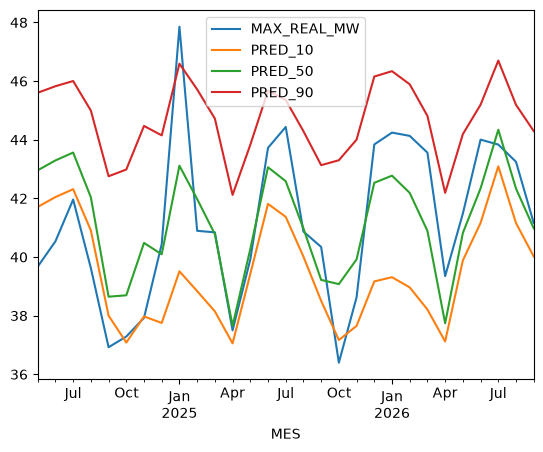

In [17]:
prueba.set_index("MES")[["MAX_REAL_MW", "PRED_10", "PRED_50", "PRED_90"]].plot()

In [18]:
prueba.loc[prueba["MAX_REAL_MW"] < prueba["PRED_10"], ["MES", "MAX_REAL_MW", "PRED_10"]]

,MES,MAX_REAL_MW,PRED_10
0,2024-05-01,39.672,41.708387
1,2024-06-01,40.536,42.045461
2,2024-07-01,41.960,42.313846
3,2024-08-01,39.622,40.908249
4,2024-09-01,36.924,38.002191
6,2024-11-01,37.926,37.973420
17,2025-10-01,36.396,37.168023


## 6. Comparación con Holt-Winters

Holt-Winters se entrena con la serie hasta el mismo corte y pronostica los mismos 29 meses.

In [19]:
serie_hw = preparar_serie_hw(serie)

In [20]:
serie_hw_entrenamiento = serie_hw.loc[:fecha_corte]

In [21]:
pronostico_hw = pronosticar_hw(serie_hw_entrenamiento, len(prueba))

In [22]:
prueba["PRED_HW"] = pronostico_hw.values

In [23]:
serie_hw_entrenamiento.tail()

MES
2023-12-01    37.004
2024-01-01    48.340
2024-02-01    45.172
2024-03-01    35.828
2024-04-01    38.104
Freq: MS, Name: MAX_REAL_MW, dtype: float64

In [24]:
pronostico_hw.head()

2024-05-01    40.705983
2024-06-01    42.399917
2024-07-01    42.066050
2024-08-01    40.923586
2024-09-01    39.804516
Freq: MS, dtype: float64

In [25]:
mae_hw =  (prueba["MAX_REAL_MW"] - prueba["PRED_HW"]).abs().mean() 
print("MAE MEDIANA: ",metricas["MAE"])
print("MAE HW: ",mae_hw)

MAE MEDIANA:  1.487125565128645
MAE HW:  1.5597011010878448


## Conclusión

- Con la climatología, el error absoluto medio de la mediana es de 1,49 MW y el 76 % de los meses quedó dentro de la banda, frente al 80 % nominal. Con la temperatura observada, los valores son casi iguales, no conocer el clima agrega poco error.
- Los meses fuera de la banda quedan casi todos por debajo: 21 % por debajo y 3 % por encima. 5 de los 7 meses por debajo con la temperatura observada son el invierno 2024 completo, seguidos. Los errores de meses consecutivos no son independientes, por lo que la banda del máximo estacional, calculada suponiendo independencia, probablemente sea más angosta de lo que debería.
- Holt-Winters tiene un error absoluto medio de 1,56 MW, alrededor de un 5 % mayor. Con 29 meses, la diferencia no es concluyente.